# CDS 3301 — C1 Regression
## Combined Cycle Power Plant Dataset

**Student:** Hillary Wekesa  
**Registration:** CT204/119566/24 | **Group:** 13

**Allocated task:** Predict net hourly electrical output (`PE`) using Linear Regression and Ridge Regression.  
**Required settings:** `random_state=9522`, `test_size=0.25`, five-fold cross-validation.

This notebook is independent of the classification and clustering notebooks. It only requires the Combined Cycle Power Plant dataset.

In [1]:

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 9522
TEST_SIZE = 0.25
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

print("Setup complete | random_state =", RANDOM_STATE, "| test_size =", TEST_SIZE)

Setup complete | random_state = 9522 | test_size = 0.25


## 1. Load the Combined Cycle Power Plant dataset

Expected UCI file: `Folds5x2_pp.xlsx`. The notebook attempts to download it automatically. If the download is unavailable, upload the Excel file.

In [6]:
from pathlib import Path
import pandas as pd

if ccpp_path is None:
    raise FileNotFoundError(
        "Dataset not found. Place Folds5x2_pp.xlsx or "
        "Folds5x2_pp.csv beside the notebook."
    )

# Detect the actual file extension
file_path = Path(ccpp_path)
extension = file_path.suffix.lower()

print("Loading dataset:", file_path.name)
print("File extension:", extension)

# Read according to the file type
if extension in [".xlsx", ".xls"]:
    df = pd.read_excel(file_path, engine="openpyxl")
elif extension == ".csv":
    df = pd.read_csv(file_path)
else:
    raise ValueError(f"Unsupported file format: {extension}")

# Clean column names
df.columns = [str(column).strip() for column in df.columns]

# Verify target column
if "PE" not in df.columns:
    raise ValueError(
        f"Expected target PE. Found columns: {list(df.columns)}"
    )

display(df.head())

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Loading dataset: Folds5x2_pp.csv
File extension: .csv


,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


Dataset shape: (9568, 5)

Column names:
['AT', 'V', 'AP', 'RH', 'PE']

Missing values:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64


## 2. Exploratory data analysis (EDA)

,count,mean,std,min,25%,50%,75%,max
AT,9568.0,19.651231,7.452473,1.81,13.5100,20.345,25.72,37.11
V,9568.0,54.305804,12.707893,25.36,41.7400,52.080,66.54,81.56
AP,9568.0,1013.259078,5.938784,992.89,1009.1000,1012.940,1017.26,1033.30
RH,9568.0,73.308978,14.600269,25.56,63.3275,74.975,84.83,100.16
PE,9568.0,454.365009,17.066995,420.26,439.7500,451.550,468.43,495.76


Missing values:


,Missing values
AT,0
V,0
AP,0
RH,0
PE,0


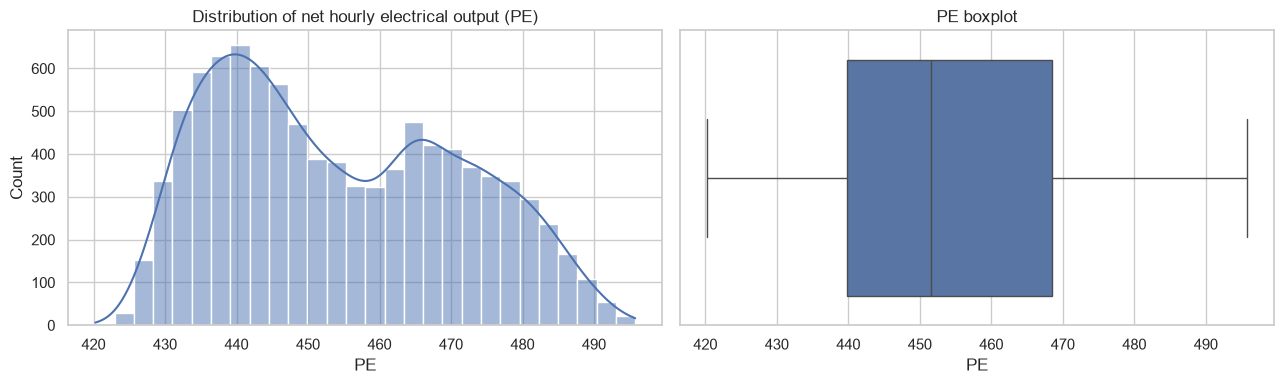

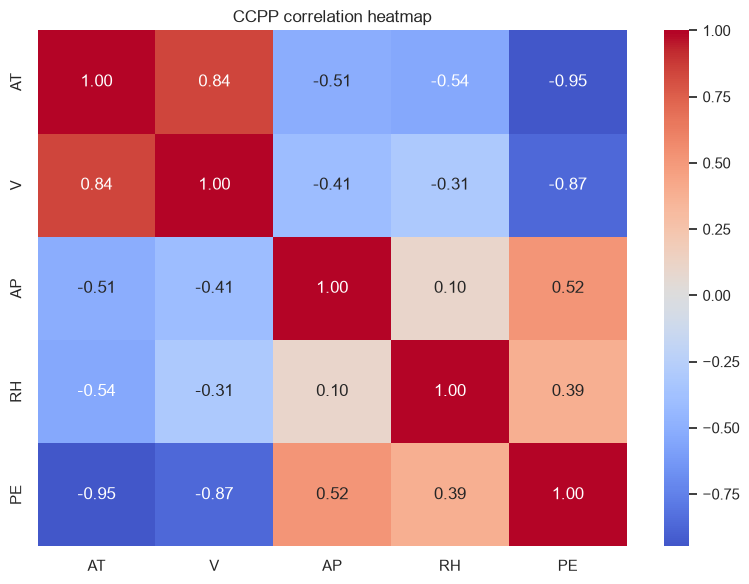

In [8]:
display(df.describe().T)
print("Missing values:")
display(df.isna().sum().to_frame("Missing values"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["PE"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of net hourly electrical output (PE)")
axes[0].set_xlabel("PE")
sns.boxplot(x=df["PE"], ax=axes[1])
axes[1].set_title("PE boxplot")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("CCPP correlation heatmap")
plt.tight_layout()
plt.show()

## 3. Preprocessing and train/test split

The standardisation and median imputation are fitted inside each pipeline to avoid data leakage.

In [9]:
X = df.drop(columns=["PE"]).select_dtypes(include=np.number).apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(df["PE"], errors="coerce")
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Features:", list(X.columns))

Training rows: 7176 | Test rows: 2392
Features: ['AT', 'V', 'AP', 'RH']


## 4. Train Linear Regression and Ridge Regression

Compare MAE, RMSE, test R-squared, and five-fold cross-validated R-squared.

In [10]:
from sklearn.linear_model import LinearRegression, Ridge

models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ])
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted, predictions = [], {}, {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted[name], predictions[name] = model, pred
    cv_result = cross_validate(model, X_train, y_train, cv=cv, scoring="r2")
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test R-squared": r2_score(y_test, pred),
        "5-fold CV R-squared (mean)": cv_result["test_score"].mean(),
        "5-fold CV R-squared (SD)": cv_result["test_score"].std()
    })

results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))

,MAE,RMSE,Test R-squared,5-fold CV R-squared (mean),5-fold CV R-squared (SD)
Model,,,,,
Linear Regression,3.6150,4.5286,0.93,0.928,0.0033
Ridge Regression,3.6151,4.5286,0.93,0.928,0.0033


## 5. Actual versus predicted values and interpretation

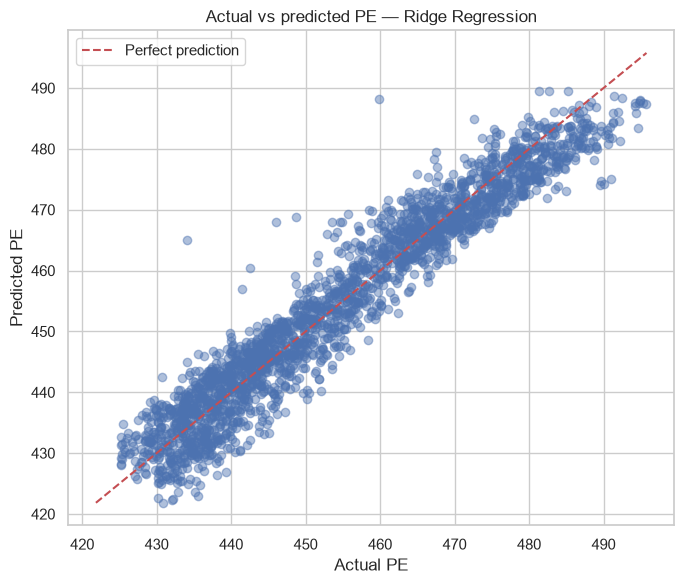

Best model by test RMSE: Ridge Regression
Interpretation: lower MAE/RMSE indicate smaller errors; higher R-squared indicates more variance explained.
Use both test metrics and cross-validation stability to justify your conclusion.


In [11]:
best_name = results["RMSE"].idxmin()
best_pred = predictions[best_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.45)
lo = min(y_test.min(), best_pred.min())
hi = max(y_test.max(), best_pred.max())
plt.plot([lo, hi], [lo, hi], "r--", label="Perfect prediction")
plt.xlabel("Actual PE")
plt.ylabel("Predicted PE")
plt.title(f"Actual vs predicted PE — {best_name}")
plt.legend()
plt.tight_layout()
plt.show()

print("Best model by test RMSE:", best_name)
print("Interpretation: lower MAE/RMSE indicate smaller errors; higher R-squared indicates more variance explained.")
print("Use both test metrics and cross-validation stability to justify your conclusion.")